# 04 · Anatomy of the saving: depth, length, time, and drift

The brief asks for "other findings". This notebook tests the lesson's four claims about reversibility directly, each against a measurement.

| lesson claim | test |
|---|---|
| §16 "The memory this saves does not depend on the number of layers." | peak memory from 2 to 64 layers, for each memory mode |
| §17 "The length at which one sequence stops fitting moves out by about two orders of magnitude." | longest sequence that trains at batch 1 |
| §16 "Nothing in between has to be kept." | the CUDA allocator's own trace through one training step |
| §16 "The rule is only marginally stable." | how far rebuilt states land from the true ones in the trained models, and what that does to the gradient |

It also checks the lesson's §1 activation constant, **34 bytes per token per hidden unit per layer**, against this model.

In [1]:
# --- setup: works on Modal, on Colab (clones the repo) and locally -------------------------
import os, sys, json, math
from pathlib import Path
if 'google.colab' in sys.modules and not Path('/content/era-v5-s13-reversibility').exists():
    !git clone -q https://github.com/sourav-dhar/era-v5-s13-reversibility /content/era-v5-s13-reversibility
    !pip -q install tiktoken datasets
    os.environ.setdefault('S13_PROFILE', 'colab')
    os.chdir('/content/era-v5-s13-reversibility/notebooks')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch, matplotlib.pyplot as plt
from s13 import store, viz, probe
from s13.profiles import P
from s13.train import run, gpu_name, device, DEFAULTS
from s13.data import prepare, data_dir
viz.style()
GiB = 2**30
PROF, CFG = store.profile(), P()
B0 = dict(CFG['base'])
CUDA = torch.cuda.is_available()
print(f'profile = {PROF} | device = {gpu_name(device())} | torch {torch.__version__}')
print('data   :', prepare(data_dir(), **CFG['data']))

profile = full | device = NVIDIA A100-SXM4-40GB | torch 2.8.0+cu128


data   : {'repo': 'HuggingFaceFW/fineweb-edu', 'subset': 'sample-10BT', 'tokenizer': 'gpt2', 'eot': 50256, 'val': {'tokens': 2000000, 'docs': 1851}, 'train': {'tokens': 52000000, 'docs': 49409}}


/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from s13 import report
from s13.train import build
FIXED_B = store.load('fixed_batch')['batch']
W = store.load('winner') or {'integrator': 'midpoint', 'h': 0.5, 'a': 0.5, 'bootstrap': 'euler', 'name': 'rev-midpoint-euler'}
REV = {k: W[k] for k in ('integrator', 'h', 'a', 'bootstrap')}
MODES = [('standard', {}), ('ckpt', {}), ('rev', REV)]

## 1 · Depth: does the reversible stack's memory really stay flat?

Batch 8 × 1,024 tokens, chunked LM head so that the head does not drown out the stack, and 2 to 64 layers. Every model is a real one, trained for one step at that depth.

[cache] depth_standard: loaded from full/depth_standard.json
[cache] depth_ckpt: loaded from full/depth_ckpt.json


[cache] depth_rev: loaded from full/depth_rev.json


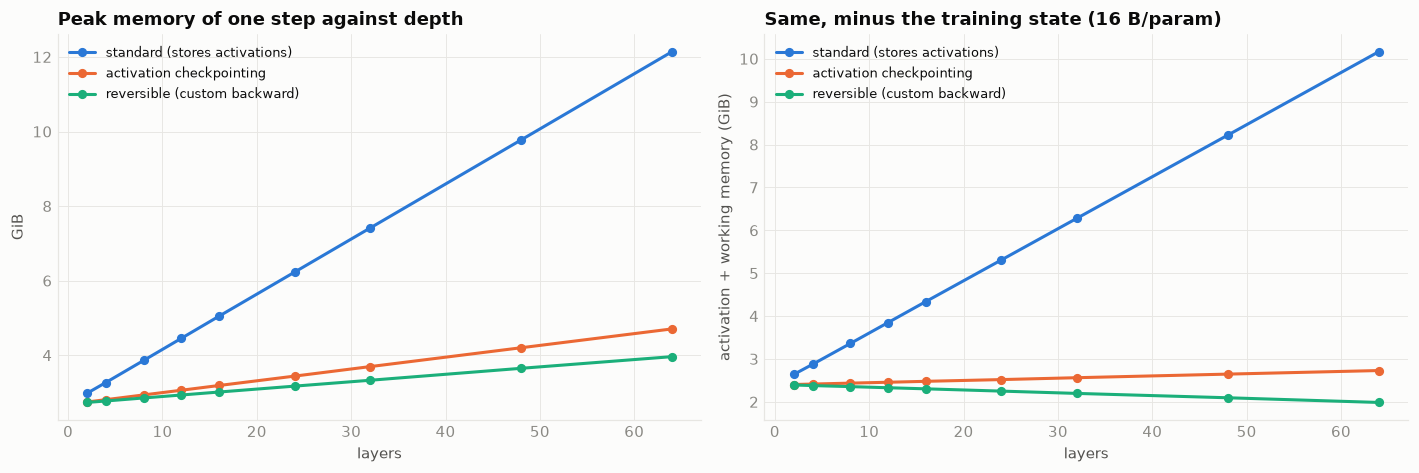

In [3]:
if CUDA:
    depth = {m: store.cached(f'depth_{m}', lambda m=m, ex=ex: probe.depth_sweep(dict(B0, mode=m, ce_chunk=4096, **ex), CFG['depths'], CFG['depth_batch']))
             for m, ex in MODES}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    for m, _ in MODES:
        pts = [p for p in depth[m] if p['peak']]
        L = np.array([p['n_layer'] for p in pts]); pk = np.array([p['peak'] for p in pts]) / GiB
        axes[0].plot(L, pk, color=viz.COLOR[m], marker='o', ms=5, label=viz.LABEL[m])
        # subtract the training state (16 B/param) to isolate activations
        state = np.array([build({**DEFAULTS, **B0, 'n_layer': int(l)}, torch.device('cpu')).n_params(False) * 16 for l in L]) / GiB
        axes[1].plot(L, pk - state, color=viz.COLOR[m], marker='o', ms=5, label=viz.LABEL[m])
    axes[0].set_title('Peak memory of one step against depth'); axes[0].set_xlabel('layers'); axes[0].set_ylabel('GiB')
    axes[1].set_title('Same, minus the training state (16 B/param)'); axes[1].set_xlabel('layers'); axes[1].set_ylabel('activation + working memory (GiB)')
    for a in axes: a.legend(fontsize=8.5)
    fig.tight_layout(); viz.save(fig, '04_depth'); plt.show()

In [4]:
if CUDA:
    toks, d = CFG['depth_batch'] * 1024, 384
    print(f"{'mode':<34}{'GiB per added layer':>21}{'bytes / token / hidden / layer':>32}")
    slopes = {}
    for m, _ in MODES:
        pts = [p for p in depth[m] if p['peak'] and p['n_layer'] >= 8]
        L = np.array([p['n_layer'] for p in pts]); pk = np.array([p['peak'] for p in pts], dtype=float)
        st = np.array([build({**DEFAULTS, **B0, 'n_layer': int(l)}, torch.device('cpu')).n_params(False) * 16 for l in L], dtype=float)
        slope = np.polyfit(L, pk - st, 1)[0]
        slopes[m] = slope
        print(f'{viz.LABEL[m]:<34}{slope/GiB:>21.4f}{slope/(toks*d):>32.1f}')
    store.save('depth_slopes', {m: s for m, s in slopes.items()})
    print("\nlesson §1 (Korthikanti et al. with FlashAttention): 34 bytes / token / hidden / layer")

mode                                GiB per added layer  bytes / token / hidden / layer


standard (stores activations)                    0.1214                            41.5


activation checkpointing                         0.0053                             1.8


reversible (custom backward)                    -0.0066                            -2.2

lesson §1 (Korthikanti et al. with FlashAttention): 34 bytes / token / hidden / layer


## 2 · Length: the longest sequence one card can train

Batch 1, chunked head, doubling the sequence until a training step fails, then bisecting to the nearest 1,024. Attention is FlashAttention via SDPA, so attention scores are never stored. What grows with length is the activations.

[cache] maxseq_standard: loaded from full/maxseq_standard.json
[cache] maxseq_ckpt: loaded from full/maxseq_ckpt.json


[cache] maxseq_rev: loaded from full/maxseq_rev.json
reversible (custom backward): reached the probe cap of 1,048,576 tokens without running out of memory


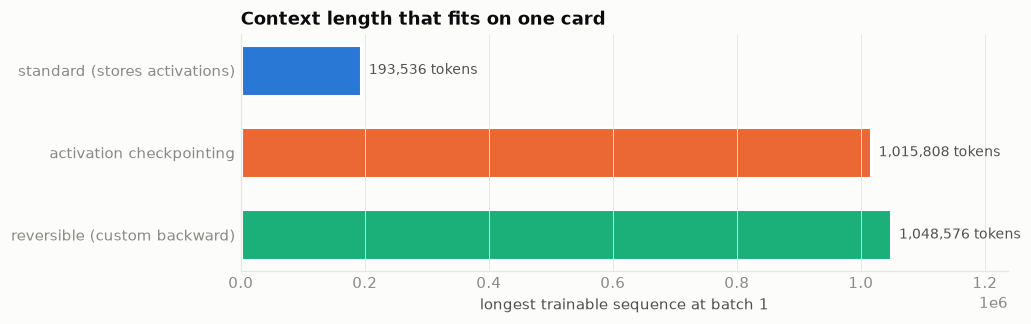

In [5]:
if CUDA:
    seqlen = {m: store.cached(f'maxseq_{m}', lambda m=m, ex=ex: probe.max_seq(dict(B0, mode=m, ce_chunk=4096, **ex), cap=CFG['seq_cap']))
              for m, ex in MODES}
    fig, ax = plt.subplots(figsize=(9, 2.8))
    names = [viz.LABEL[m] for m, _ in MODES]; vals = [seqlen[m]['max_seq'] for m, _ in MODES]
    report.hbars(ax, names, vals, [viz.COLOR[m] for m, _ in MODES], fmt='{:,.0f} tokens', xlabel='longest trainable sequence at batch 1')
    for m, _ in MODES:
        if seqlen[m]['capped']: print(f'{viz.LABEL[m]}: reached the probe cap of {CFG["seq_cap"]:,} tokens without running out of memory')
    ax.set_title('Context length that fits on one card'); viz.save(fig, '04_maxseq'); plt.show()

## 3 · Time: memory through one training step

The CUDA caching allocator records every allocation and free. Marker allocations of unusual sizes split the trace into forward, backward and optimizer. The step is a steady-state one, so the Adam moments already exist. Batch is the fixed batch, with the full-logit head, exactly as trained in notebooks 01 and 02.

[cache] timeline_standard: loaded from full/timeline_standard.json


[cache] timeline_ckpt: loaded from full/timeline_ckpt.json
[cache] timeline_rev: loaded from full/timeline_rev.json


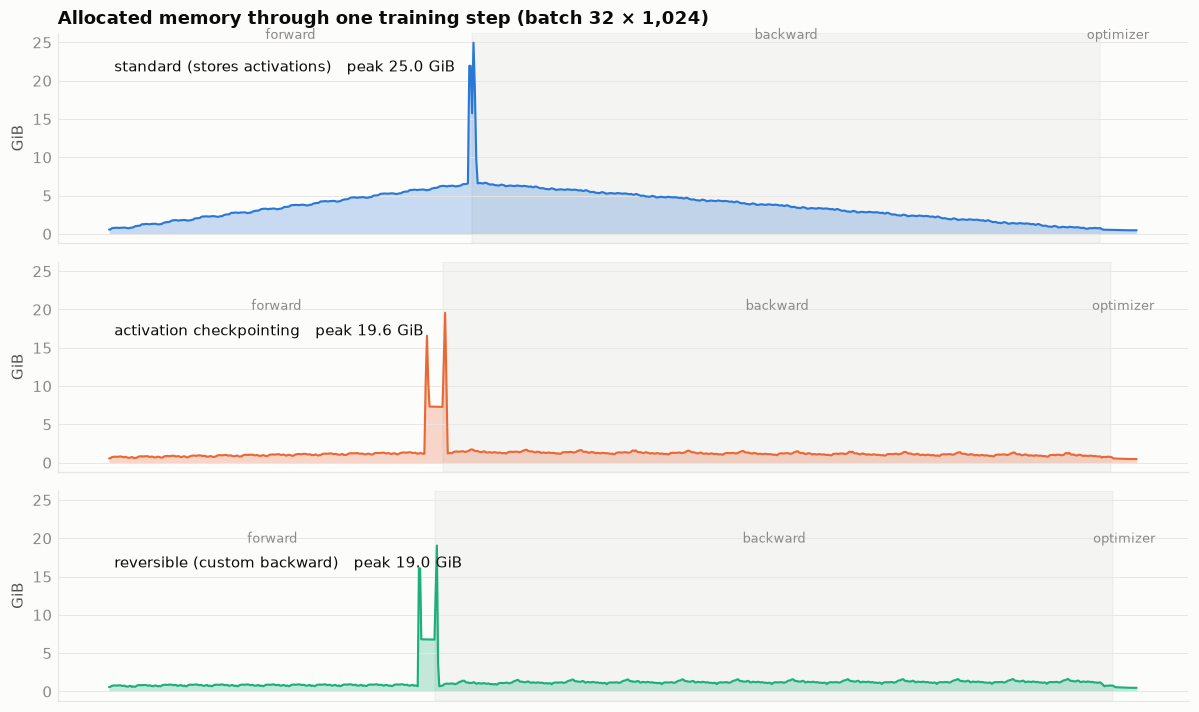

In [6]:
if CUDA:
    tl = {m: store.cached(f'timeline_{m}', lambda m=m, ex=ex: probe.timeline(dict(B0, mode=m, **ex), FIXED_B)) for m, ex in MODES}
    fig, axes = plt.subplots(len(MODES), 1, figsize=(11, 6.6), sharey=True)
    for ax, (m, _) in zip(axes, MODES):
        b = np.array(tl[m]['bytes']) / GiB; x = np.linspace(0, 1, len(b))
        ax.fill_between(x, 0, b, color=viz.COLOR[m], alpha=0.25, lw=0); ax.plot(x, b, color=viz.COLOR[m], lw=1.4)
        ph = tl[m]['phases']; n = len(b)
        for (nm, i0), (_, i1) in zip(list(ph.items())[:-1], list(ph.items())[1:]):
            ax.axvspan(i0 / n, i1 / n, color='#000', alpha=0.03 if nm == 'backward' else 0)
            ax.text((i0 + i1) / 2 / n, b.max() * 1.02, nm, ha='center', fontsize=8.5, color=viz.MUTED)
        ax.set_ylabel('GiB'); ax.text(0.005, b.max() * 0.85, f'{viz.LABEL[m]}   peak {tl[m]["peak"]/GiB:.1f} GiB', fontsize=9.5, color=viz.INK)
        ax.set_xticks([])
    axes[0].set_title(f'Allocated memory through one training step (batch {FIXED_B} × 1,024)')
    fig.tight_layout(); viz.save(fig, '04_timeline'); plt.show()

## 4 · Drift: how exact is "exact" in bf16?

The custom backward is exact in exact arithmetic, and tests confirm it to 1e-9 in float64. In training, each block runs in bf16 autocast. A rebuilt state therefore differs from the true one by rounding, and §1 of notebook 02 predicts how each integrator amplifies that rounding as the reconstruction walks down the stack.

For every **trained** variant from notebook 02, on held-out tokens, this section measures:

* the relative error of every rebuilt state $\lVert \hat s_k - s_k \rVert / \lVert s_k \rVert$, with the residual stream held in fp32 (as trained) and in bf16,
* the cosine between the reversible gradient and plain autograd's gradient for every layer.

In [7]:
from s13.data import Windows
val = Windows(data_dir() / 'val.bin', B0.get('seq', 1024), seed=7)
idx, tgt = val.get(0, 4, device())
drift = {}
for name, integ, h, a, boot in CFG['variants']:
    ck = store.ckpt_dir() / f'rev-{name}.pt'
    if not ck.exists():
        continue
    def measure(ck=ck):
        blob = torch.load(ck, map_location=device())
        m = build(blob['cfg'], device()); m.load_state_dict(blob['state']); m.eval()
        out = {'fp32_state': probe.state_drift(m, idx), 'bf16_state': probe.state_drift(m, idx, state_dtype='bfloat16')}
        m.train(); out['grad'] = probe.grad_fidelity(m, idx, tgt)
        return out
    drift[name] = store.cached(f'drift_{name}', measure)
print('measured', list(drift))

[cache] drift_midpoint-euler: loaded from full/drift_midpoint-euler.json


[cache] drift_midpoint-nokick: loaded from full/drift_midpoint-nokick.json


[cache] drift_blend-euler: loaded from full/drift_blend-euler.json
[cache] drift_blend-nokick: loaded from full/drift_blend-nokick.json


[cache] drift_blend-libdefault: loaded from full/drift_blend-libdefault.json


[cache] drift_leapfrog-euler: loaded from full/drift_leapfrog-euler.json


[cache] drift_leapfrog-nokick: loaded from full/drift_leapfrog-nokick.json
measured ['midpoint-euler', 'midpoint-nokick', 'blend-euler', 'blend-nokick', 'blend-libdefault', 'leapfrog-euler', 'leapfrog-nokick']


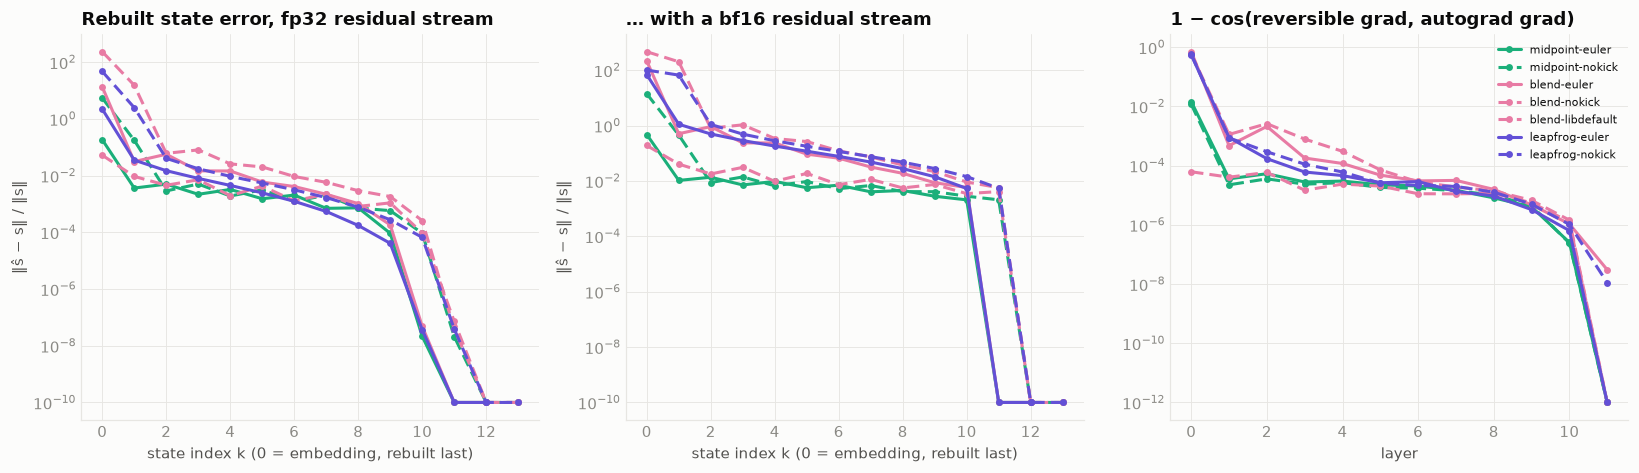

variant               max state err fp32  max state err bf16    min grad cos
midpoint-euler                  1.84e-01            4.77e-01        0.985469
midpoint-nokick                 5.46e+00            1.42e+01        0.988208
blend-euler                     1.35e+01            2.17e+02        0.295549
blend-nokick                    2.34e+02            4.67e+02        0.404873
blend-libdefault                5.25e-02            1.92e-01        0.999938
leapfrog-euler                  2.22e+00            6.93e+01        0.451253
leapfrog-nokick                 4.72e+01            1.02e+02        0.425046


In [8]:
if drift:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    for name, integ, h, a, boot in CFG['variants']:
        if name not in drift: continue
        col, ls = viz.COLOR[integ], viz.DASH[boot]
        e32, e16 = drift[name]['fp32_state']['rel_err'], drift[name]['bf16_state']['rel_err']
        axes[0].semilogy(range(len(e32)), np.maximum(e32, 1e-10), color=col, ls=ls, marker='o', ms=3.5, label=name)
        axes[1].semilogy(range(len(e16)), np.maximum(e16, 1e-10), color=col, ls=ls, marker='o', ms=3.5, label=name)
        g = [r for r in drift[name]['grad'] if r['layer'] >= 0]
        axes[2].semilogy([r['layer'] for r in g], [max(1 - r['cos'], 1e-12) for r in g], color=col, ls=ls, marker='o', ms=3.5, label=name)
    axes[0].set_title('Rebuilt state error, fp32 residual stream'); axes[1].set_title('… with a bf16 residual stream')
    axes[2].set_title('1 − cos(reversible grad, autograd grad)')
    for a_ in axes[:2]: a_.set_xlabel('state index k (0 = embedding, rebuilt last)'); a_.set_ylabel('‖ŝ − s‖ / ‖s‖')
    axes[2].set_xlabel('layer'); axes[2].legend(fontsize=7.5)
    fig.tight_layout(); viz.save(fig, '04_drift'); plt.show()
    print(f"{'variant':<20}{'max state err fp32':>20}{'max state err bf16':>20}{'min grad cos':>16}")
    for name in drift:
        g = drift[name]['grad']
        print(f"{name:<20}{max(drift[name]['fp32_state']['rel_err']):>20.2e}{max(drift[name]['bf16_state']['rel_err']):>20.2e}{min(r['cos'] for r in g):>16.6f}")

### Reading the drift plots

* The top two states are stored, so their error is exactly 0. Error then enters at the first reconstruction and is carried down the stack by the recurrence.
* **Midpoint** carries error forward without amplifying it ($|1/z| = 1$).
* **Blend a = 0.5** doubles it every layer ($|1/z| = 2$), as predicted in notebook 02 §1. That is the price of a damped *forward* rule, and the reason Gal et al. require $|\alpha| = 1$.
* A **bf16 residual stream** would halve the size of the two stored states. The middle panel shows what it costs in reconstruction error, which is why this repo keeps the stream in fp32 and only the blocks in bf16.
* The gradient cosine is the number that matters for training. A cosine of 0.9999 is far more agreement than one mini-batch's gradient has with the next one's.

## 5 · Where the error lives, and a fix

The per-layer cosines above are close to 1 everywhere except **the embedding and layer 0**. The state norms explain why. The embedding state $s_0$ has a norm near 1. The states above it grow to 50–1,000, and leapfrog's grow almost linearly with depth. Rebuilding $s_0$ means subtracting two large numbers to get a small one, which is catastrophic cancellation. The bf16 rounding of the upper blocks, roughly $2^{-8}$ of a large number, then outweighs the state being recovered.

That suggests a cheap fix: **anchor the bottom of the stack**, storing $s_0$ and $s_1$ next to the top two states. It costs two more fp32 states, 3 MiB per 1,024-token sequence. The depth-independence is untouched, and the custom backward stays exact in float64 (`tests/test_reversible.py` covers all six anchored variants).

Below:

* the same trained checkpoints, measured again with anchoring on,
* the full precision path (autocast off) as a control, to confirm that bf16 is the source of the error,
* then all three integrators retrained with anchoring on the same 50M tokens.

In [9]:
from dataclasses import replace
anch = {}
for name, integ, h, a, boot in CFG['variants']:
    ck = store.ckpt_dir() / f'rev-{name}.pt'
    if not ck.exists():
        continue
    def measure(ck=ck):
        blob = torch.load(ck, map_location=device())
        m = build(blob['cfg'], device()); m.load_state_dict(blob['state'])
        out = {'fp32_noamp': probe.state_drift(m, idx, amp=False)}
        m.cfg.rev = replace(m.cfg.rev, anchor=True)
        out['grad_anchored'] = probe.grad_fidelity(m, idx, tgt)
        return out
    anch[name] = store.cached(f'drift_anchor_{name}', measure)
print(f"{'variant':<18}{'layer-0 cos':>13}{'anchored':>10}{'embed cos':>11}{'anchored':>10}{'max state err, no autocast':>28}")
for name in anch:
    g0 = {r['layer']: r['cos'] for r in drift[name]['grad']}; g1 = {r['layer']: r['cos'] for r in anch[name]['grad_anchored']}
    print(f"{name:<18}{g0[0]:>13.4f}{g1[0]:>10.4f}{g0[-1]:>11.4f}{g1[-1]:>10.4f}{max(anch[name]['fp32_noamp']['rel_err']):>28.2e}")

variant             layer-0 cos  anchored  embed cos  anchored  max state err, no autocast
midpoint-euler           0.9855    1.0000     0.9989    1.0000                    2.28e-05
midpoint-nokick          0.9882    1.0000     0.9990    1.0000                    8.78e-04
blend-euler              0.2955    1.0000     0.8842    1.0000                    4.96e-03
blend-nokick             0.4049    0.9999     0.8651    0.9999                    4.76e-01
blend-libdefault         0.9999    1.0000     1.0000    1.0000                    6.75e-06
leapfrog-euler           0.4513    1.0000     0.9378    1.0000                    1.12e-03
leapfrog-nokick          0.4250    0.9999     0.9313    1.0000                    3.98e-02


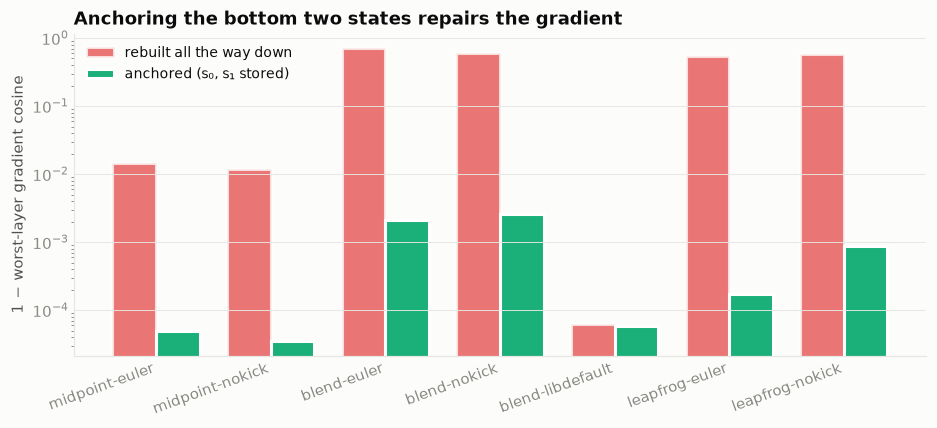

In [10]:
if anch:
    names = list(anch)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    x = np.arange(len(names)); w = 0.38
    worst0 = [1 - min(r['cos'] for r in drift[n]['grad']) for n in names]
    worst1 = [1 - min(r['cos'] for r in anch[n]['grad_anchored']) for n in names]
    ax.bar(x - w/2, np.maximum(worst0, 1e-9), w, color='#e34948', alpha=.75, label='rebuilt all the way down', edgecolor='white', linewidth=2)
    ax.bar(x + w/2, np.maximum(worst1, 1e-9), w, color=viz.COLOR['rev'], label='anchored (s₀, s₁ stored)', edgecolor='white', linewidth=2)
    ax.set_yscale('log'); ax.set_xticks(x, names, rotation=20, ha='right'); ax.grid(axis='x', visible=False)
    ax.set_ylabel('1 − worst-layer gradient cosine'); ax.legend(); ax.set_title('Anchoring the bottom two states repairs the gradient')
    viz.save(fig, '04_anchor_fidelity'); plt.show()

midpoint-nokick    val 4.5064 → anchored 4.4746  (Δ -0.0318; vs standard +0.0266)   peak 19.05 → 19.10 GiB   162,563 → 162,988 tok/s


blend-euler        val 4.8957 → anchored 4.4442  (Δ -0.4515; vs standard -0.0038)   peak 19.05 → 19.14 GiB   157,350 → 157,082 tok/s


leapfrog-euler     val 4.5299 → anchored 4.4207  (Δ -0.1092; vs standard -0.0273)   peak 19.05 → 19.14 GiB   157,239 → 157,618 tok/s


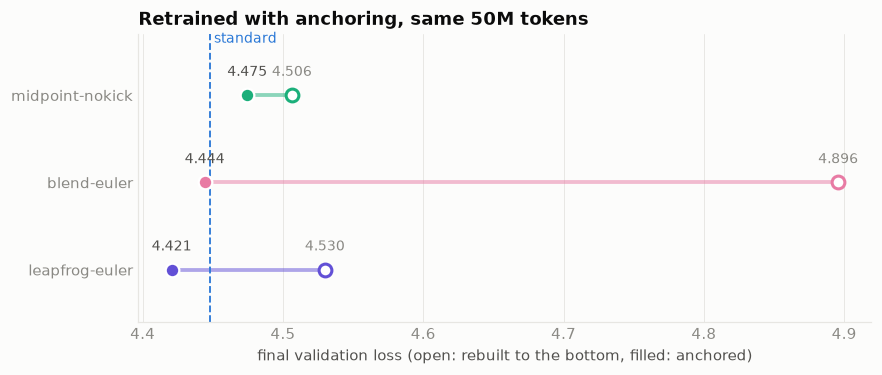

In [11]:
pairs = [('midpoint-nokick', 'anc-midpoint-nokick'), ('blend-euler', 'anc-blend-euler'), ('leapfrog-euler', 'anc-leapfrog-euler')]
base_r = store.load('run_baseline')
rows = []
for plain, anc_ in pairs:
    a_, b_ = store.load(f'run_rev-{plain}'), store.load(f'run_rev-{anc_}')
    if a_ and b_:
        rows.append((plain, a_, b_))
        print(f"{plain:<18} val {a_['final_val']:.4f} → anchored {b_['final_val']:.4f}  (Δ {b_['final_val']-a_['final_val']:+.4f}; "
              f"vs standard {b_['final_val']-base_r['final_val']:+.4f})   peak {a_['peak_mem_bytes']/GiB:.2f} → {b_['peak_mem_bytes']/GiB:.2f} GiB   "
              f"{a_['tok_per_s']:,.0f} → {b_['tok_per_s']:,.0f} tok/s")
if rows:
    fig, ax = plt.subplots(figsize=(8.6, 3.4))
    y = np.arange(len(rows))[::-1]
    for yi, (n, a_, b_) in zip(y, rows):
        col = viz.COLOR[a_['cfg']['integrator']]
        ax.plot([a_['final_val'], b_['final_val']], [yi, yi], color=col, lw=2.5, alpha=.5)
        ax.scatter([a_['final_val']], [yi], s=70, color='white', edgecolor=col, linewidth=2, zorder=3)
        ax.scatter([b_['final_val']], [yi], s=80, color=col, edgecolor='white', linewidth=1.5, zorder=3)
        ax.text(b_['final_val'], yi + 0.22, f"{b_['final_val']:.3f}", ha='center', fontsize=9, color=viz.INK2)
        ax.text(a_['final_val'], yi + 0.22, f"{a_['final_val']:.3f}", ha='center', fontsize=9, color=viz.MUTED)
    ax.axvline(base_r['final_val'], color=viz.COLOR['standard'], ls='--', lw=1.2); ax.text(base_r['final_val'], len(rows) - 0.4, ' standard', color=viz.COLOR['standard'], fontsize=9)
    ax.set_yticks(y, [r[0] for r in rows]); ax.grid(axis='y', visible=False); ax.set_ylim(-0.6, len(rows) - 0.3)
    ax.set_xlabel('final validation loss (open: rebuilt to the bottom, filled: anchored)'); ax.set_title('Retrained with anchoring, same 50M tokens')
    viz.save(fig, '04_anchor_runs'); plt.show()

### Is a 0.03 gap real? A second seed

Each run above is one seed. To check whether the anchored integrators really reach the standard model, three of the configurations were trained again with a different initialisation (`seed = 1`). The data order is fixed separately, so it stays the same. The spread between seeds is the noise floor that any claimed difference has to clear.

In [12]:
seed_pairs = [('standard', 'baseline', 'baseline-s1'), ('midpoint, no-kick', 'rev-midpoint-nokick', 'rev-midpoint-nokick-s1'),
              ('leapfrog, Euler start, anchored', 'rev-anc-leapfrog-euler', 'rev-anc-leapfrog-euler-s1')]
print(f"{'configuration':<34}{'seed 0':>9}{'seed 1':>9}{'mean':>9}{'|Δ seeds|':>11}")
seed_rows = {}
for lab, k0, k1 in seed_pairs:
    a_, b_ = store.load(f'run_{k0}'), store.load(f'run_{k1}')
    if a_ and b_:
        seed_rows[lab] = (a_['final_val'], b_['final_val'])
        print(f"{lab:<34}{a_['final_val']:>9.4f}{b_['final_val']:>9.4f}{(a_['final_val']+b_['final_val'])/2:>9.4f}{abs(a_['final_val']-b_['final_val']):>11.4f}")

configuration                        seed 0   seed 1     mean  |Δ seeds|


standard                             4.4480   4.4336   4.4408     0.0144


midpoint, no-kick                    4.5064   4.5197   4.5130     0.0133


leapfrog, Euler start, anchored      4.4207   4.4355   4.4281     0.0148
